In [1]:
import numpy as np
import matplotlib.pyplot as pl
import dispatch
import os

In [2]:
data = '../data'
run = 'bifrost'

In [4]:
ss = []
start = 0
end = sum(os.path.isdir(data+'/'+run+'/'+i) for i in os.listdir(data+'/'+run)) - 3 
print(end)
step = 1
for i in range(start,end,step):
    s = dispatch.snapshot(i,run=run,data=data, copy=True)
    ss.append(s)

-1


In [5]:
pl.figure(1, figsize=(11,7))

<Figure size 792x504 with 0 Axes>

<Figure size 792x504 with 0 Axes>

In [6]:
for it in range(start,end,step):
        print('it=',it)
        pl.clf()
        pl.suptitle('iout={}                            time={:5.1f}'.format(it,ss[it].time))
        #print "e, max,min,mean", np.max(pp[1].data[:,:,:,0]), np.min(pp[1].data[:,:,:,0]), np.mean(pp[1].data[:,:,:,0])
        #for ip in range(num_patches):
        #    pp = ss[it].patches[ip]
        #    #density = pp.data[0]
        pl.subplot(1,4,1); im3(ss[it], 0, 470, 530 ,'d')#,ylim0,ylim1)
        pl.subplot(1,4,2); im3(ss[it], 1, -.20, +.20 ,'px' )
        #pl.subplot(1,4,2); im3(ss[it], 7, 0.00, 0.08, 'bz')#,ylim0,ylim1)
        pl.subplot(1,4,3); im3(ss[it], 2, -.20, +.20, 'py')#,ylim0,ylim1)
        pl.subplot(1,4,4); im3(ss[it], 3, -.20, +.20, 'pz')#,ylim0,ylim1)
        #pl.subplot(1,4,4); im3(pp, 4, -.20, +.20, 'pz')
        if it==0:
            pl.tight_layout()
        pl.draw()
        pl.pause(0.001)
        if save_plots == 'True':
            #pl.savefig('images/border/border_xz_plan'+str(iout))
            pl.savefig("{}/{:03d}".format(run,it))

In [7]:
def im3(pp,iv,vmin,vmax,varname): #,ylim0=0,ylim1=3):
    #pl.xlim(0,1)#; pl.ylim(ylim0,ylim1)
    num_patches = len(pp.patches)
    n=pp.patches[0].n
    g=pp.patches[0].ng
    m=int(n[1]/2 -1)
    pos_arr = np.zeros([int(pp.patches[0].box[0]),int(pp.patches[0].box[1]),int(pp.patches[0].box[2])])
    patch_arr = np.zeros([np.shape(pos_arr)[0]*n[0], np.shape(pos_arr)[1]*n[1], np.shape(pos_arr)[2]*n[2]])
    for ip in range(num_patches):
        p = pp.patches[ip]
        position = [int(p.position[0]-0.5), int(p.position[1]-0.5), int(p.position[2]-0.5)]
        pos_arr[position[0], position[1], position[2]] = p.id
        data=p.data[iv] if hasattr(p,'data') else p.var(iv)
        no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        patch_arr[position[0]*n[0]:position[0]*n[0]+n[0],position[1]*n[1]:position[1]*n[1]+n[1],position[2]*n[2]:position[2]*n[2]+n[2]] = no_gz#.transpose()
    #print(pos_arr)
    #print(np.shape(patch_arr.transpose()))
    #final = np.sum(patch_arr,axis=1).transpose() #.transpose().reshape(n[0]*3,n[0]*3)
    final = patch_arr[:,15,:].transpose()
    pl.imshow(final, cmap='jet')
    pl.title(varname); 
    pl.colorbar()

IndexError: list index out of range

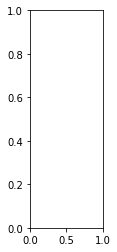

In [8]:
pl.subplot(1,4,1); im3(ss[0], 0, 470, 530 ,'d')#,ylim0,ylim1)

In [9]:
n=ss[0].patches[0].n
num_patches = len(ss[0].patches)
g=ss[0].patches[0].ng

IndexError: list index out of range

In [10]:
m=int(n[1]/2 -1)
pos_arr = np.zeros([int(ss[0].box[0]),int(ss[0].box[1]),int(ss[0].box[2])])
patch_arr = np.zeros([np.shape(pos_arr)[0]*n[0], np.shape(pos_arr)[1]*n[1], np.shape(pos_arr)[2]*n[2]])

NameError: name 'n' is not defined

In [11]:
pp=ss[0]
iv=0

IndexError: list index out of range

In [12]:
for ip in range(num_patches):
        p = pp.patches[ip]
        position = [int(p.position[0]-0.5), int(p.position[1]-0.5), int(p.position[2]-0.5)]
        pos_arr[position[0], position[1], position[2]] = p.id
        data=p.data[iv] if hasattr(p,'data') else p.var(iv)
        no_gz=data[g[0]:-g[0],g[1]:-g[1],g[2]:-g[2]]
        patch_arr[position[0]*n[0]:position[0]*n[0]+n[0],position[1]*n[1]:position[1]*n[1]+n[1],position[2]*n[2]:position[2]*n[2]+n[2]] = no_gz#.transpose()

NameError: name 'num_patches' is not defined

In [13]:
p=pp.patches[0]

NameError: name 'pp' is not defined

In [14]:
position = [int(p.position[0]-0.5), int(p.position[1]-0.5), int(p.position[2]-0.5)]
pos_arr[position[0], position[1], position[2]] = p.id

NameError: name 'p' is not defined

In [15]:
p.var(0)

NameError: name 'p' is not defined

it= 0


ValueError: could not broadcast input array from shape (24,24,24) into shape (32,32,32)

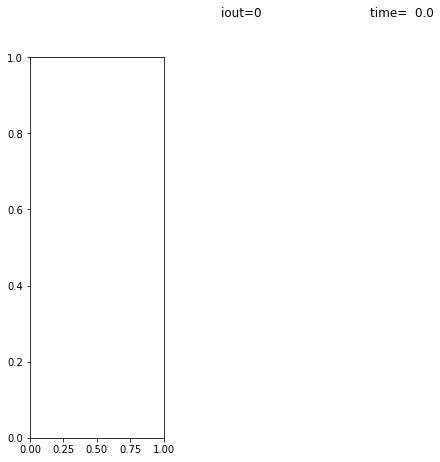

In [115]:
%run ./input3.py

In [5]:
import dispatch
import dispatch.select as ds
import dispatch.graphics as dg
import dispatch.yt as dyt
import numpy as np
import yt as yt
import matplotlib.pyplot as pl

In [96]:
#bbox = np.array([[-.5, .5], [-1., 1.], [-0.0015, 0.0015]])
#bbox = np.array([[-256,256], [-64,64], [-1,1]])
bbox = np.array([[0,1], [0,1], [0,3]])
data='../data'
run = 'input2'
#run = ''
snap=3

      yt patches: 27
domain_dimesions: [3, 3, 3]


yt : [INFO     ] 2019-10-21 12:09:54,424 Parameters: current_time              = 0.003
yt : [INFO     ] 2019-10-21 12:09:54,424 Parameters: domain_dimensions         = [3 3 3]
yt : [INFO     ] 2019-10-21 12:09:54,425 Parameters: domain_left_edge          = [-1. -1. -1.]
yt : [INFO     ] 2019-10-21 12:09:54,426 Parameters: domain_right_edge         = [3. 3. 3.]
yt : [INFO     ] 2019-10-21 12:09:54,427 Parameters: cosmological_simulation   = 0.0
yt : [INFO     ] 2019-10-21 12:09:55,188 xlim = -1.000000 2.000000
yt : [INFO     ] 2019-10-21 12:09:55,189 ylim = -1.000000 2.000000
yt : [INFO     ] 2019-10-21 12:09:55,190 xlim = -1.000000 2.000000
yt : [INFO     ] 2019-10-21 12:09:55,191 ylim = -1.000000 2.000000
yt : [INFO     ] 2019-10-21 12:09:55,192 Making a fixed resolution buffer of (('stream', 'ez')) 800 by 800
yt : [WARNING  ] 2019-10-21 12:09:55,214 Plot image for field ('stream', 'ez') has both positive and negative values. Min = -0.001485, Max = 0.001489.
yt : [WARNING  ] 2019-10-2


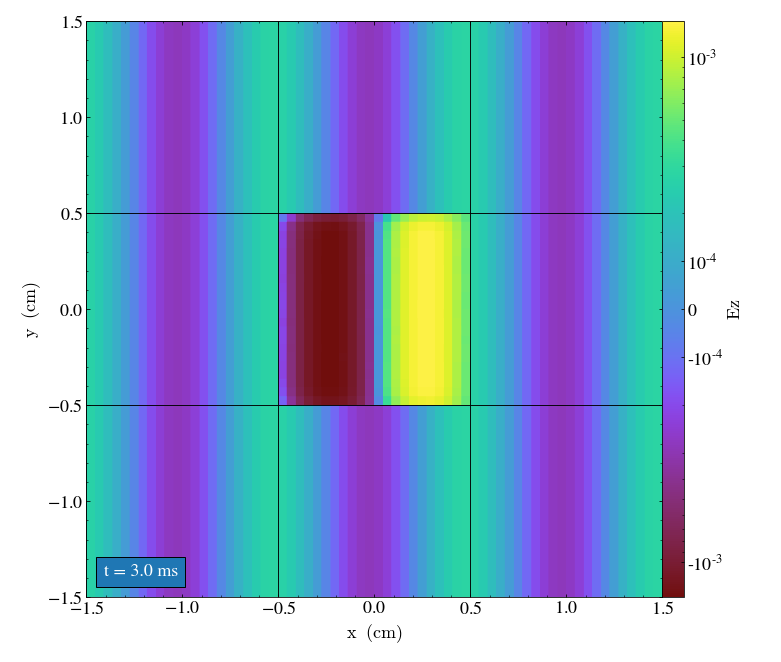

In [103]:
ds = dyt.open_amr(iout=snap,run=run,data=data,verbose=1,copy=True)
center = [0.5,0.5,0.5]
#s=dispatch.snapshot(snap,run,data, copy=True, verbose=1)
#dic=dyt.patches(s)
varfield = 'ez'
#ds = yt.load_amr_grids(dic, s.cartesian.dims, length_unit=(s.units.l,'cm'), mass_unit=(s.units.m,'g'), time_unit=(s.units.t,'s'), \
#                       bbox=bbox,periodicity=(True,True,False))
slc=yt.SlicePlot(ds=ds,axis="z",fields=[varfield],center=center,width = ((3.),(3.)))
#slc.set_cmap(varfield,"inferno")
#slc.set_cmap(varfield,"gist_gray")
#slc.set_log(varfield,False)
#slc.set_zlim("temperature", 1e3, 1e4)
#slc.annotate_streamlines('magnetic_field_x', 'magnetic_field_y',field_color='b_mag',density=5.3)#plot_args={'color':'grey'})
#slc.annotate_quiver('velocity_x', 'velocity_y', factor=24, normalize=False)
#slc.annotate_contour('b_mag', take_log=True)
slc.annotate_grids()
#slc.show()
slc.annotate_timestamp()
slc.show()


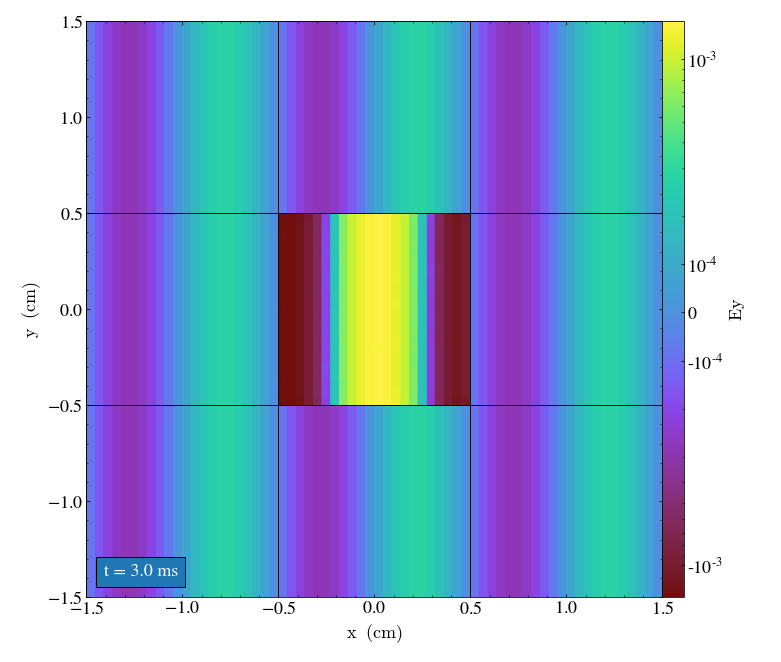

In [102]:
slc.show()

snap=1
s=dispatch.snapshot(iout=snap, data=data, run=run,copy=True, verbose=1)

In [42]:
s=dispatch.snapshot(iout=snap, data=data, run=run,copy=True, verbose=1)

parsing ../data/input3/00001/snapshot.nml
  parsing io_nml
    adding property io
  parsing snapshot_nml
  parsing idx_nml
    adding property idx
  parsing units_nml
    adding property units
  parsing cartesian_params
    adding property cartesian
parsing ../data/input3/00001/rank_00000_patches.nml
  added 3 patches

timer:
snapshot metadata:   0.020 sec
         _patches:   0.010 sec


In [47]:
s.patches[0].keys

{'letters': ['d',
  'e',
  'et',
  's',
  'px',
  'py',
  'pz',
  'bx',
  'by',
  'bz',
  'qr',
  'tt',
  'phi',
  'p1',
  'p2',
  'p3',
  'b1',
  'b2',
  'b3'],
 'numbers': [0, 4, -1, 4, 1, 2, 3, 5, 6, 7, -1, -1, -1, 1, 2, 3, 5, 6, 7],
 'expressions': ['ux', 'uy', 'uz', 'u1', 'u2', 'u3', 'ee', 'E'],
 'aux': dict_keys([])}